In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/Loan_default.csv")


In [3]:
print(df.shape)
df.head()

(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [4]:
target = "Default"

## Remove LoanID from the modeling data

In [5]:
df_model = df.drop(columns=["LoanID"]).copy()

## Create LoanToIncomeRatio

In [6]:
df_model["LoanToIncomeRatio"] = (
    df_model["LoanAmount"] / df_model["Income"]
)

In [7]:
df_model[["LoanAmount", "Income", "LoanToIncomeRatio"]].head()

,LoanAmount,Income,LoanToIncomeRatio
0,50587,85994,0.588262
1,124440,50432,2.467481
2,129188,84208,1.534154
3,44799,31713,1.412638
4,9139,20437,0.447179


## Create EmploymentYears

In [8]:
df_model["EmploymentYears"] = (
    df_model["MonthsEmployed"] / 12
)

In [9]:
df_model[["MonthsEmployed", "EmploymentYears"]].head()

,MonthsEmployed,EmploymentYears
0,80,6.666667
1,15,1.250000
2,26,2.166667
3,0,0.000000
4,8,0.666667


## Create estimated monthly income

In [10]:
df_model["MonthlyIncome"] = (
    df_model["Income"] / 12
)

In [11]:
df_model[["Income", "MonthlyIncome"]].head()

,Income,MonthlyIncome
0,85994,7166.166667
1,50432,4202.666667
2,84208,7017.333333
3,31713,2642.750000
4,20437,1703.083333


## Create credit-score bands

In [12]:
df_model["CreditRiskBand"] = pd.cut(
    df_model["CreditScore"],
    bins=[0, 579, 669, 739, 799, 850],
    labels=[
        "Poor",
        "Fair",
        "Good",
        "Very Good",
        "Excellent"
    ]
)

In [13]:
df_model["CreditRiskBand"].value_counts()

CreditRiskBand
Poor         130223
Fair          41847
Good          32073
Very Good     27736
Excellent     23468
Name: count, dtype: int64

## Create DTI risk bands

In [14]:
df_model["DTIRiskBand"] = pd.cut(
    df_model["DTIRatio"],
    bins=[0, 0.30, 0.50, 0.70, 1.00],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ],
    include_lowest=True
)

In [15]:
df_model["DTIRiskBand"].value_counts()

DTIRiskBand
Low          65248
Moderate     63970
High         63781
Very High    62348
Name: count, dtype: int64

## Check the engineered features

In [16]:
new_features = [
    "LoanToIncomeRatio",
    "EmploymentYears",
    "MonthlyIncome",
    "CreditRiskBand",
    "DTIRiskBand"
]

df_model[new_features].head(10)

,LoanToIncomeRatio,EmploymentYears,MonthlyIncome,CreditRiskBand,DTIRiskBand
0,0.588262,6.666667,7166.166667,Poor,Moderate
1,2.467481,1.250000,4202.666667,Poor,High
2,1.534154,2.166667,7017.333333,Poor,Moderate
3,1.412638,0.000000,2642.750000,Very Good,Low
4,0.447179,0.666667,1703.083333,Fair,Very High
5,1.001661,1.500000,7524.833333,Good,Low
6,1.592123,6.666667,9265.666667,Poor,Low
7,1.226408,5.583333,10566.833333,Poor,Moderate
8,2.196205,6.916667,3504.416667,Excellent,Low
9,1.720915,9.500000,11065.333333,Poor,Moderate


## Check for invalid engineered values

#### Loan-to-income

In [17]:
df_model["LoanToIncomeRatio"].describe()

count    255347.000000
mean          2.177480
std           2.178357
min           0.033749
25%           0.803628
50%           1.546720
75%           2.671744
max          16.532460
Name: LoanToIncomeRatio, dtype: float64

In [18]:
np.isinf(df_model["LoanToIncomeRatio"]).sum()

np.int64(0)

In [19]:
df_model["LoanToIncomeRatio"].isnull().sum()

np.int64(0)

## Check correlations

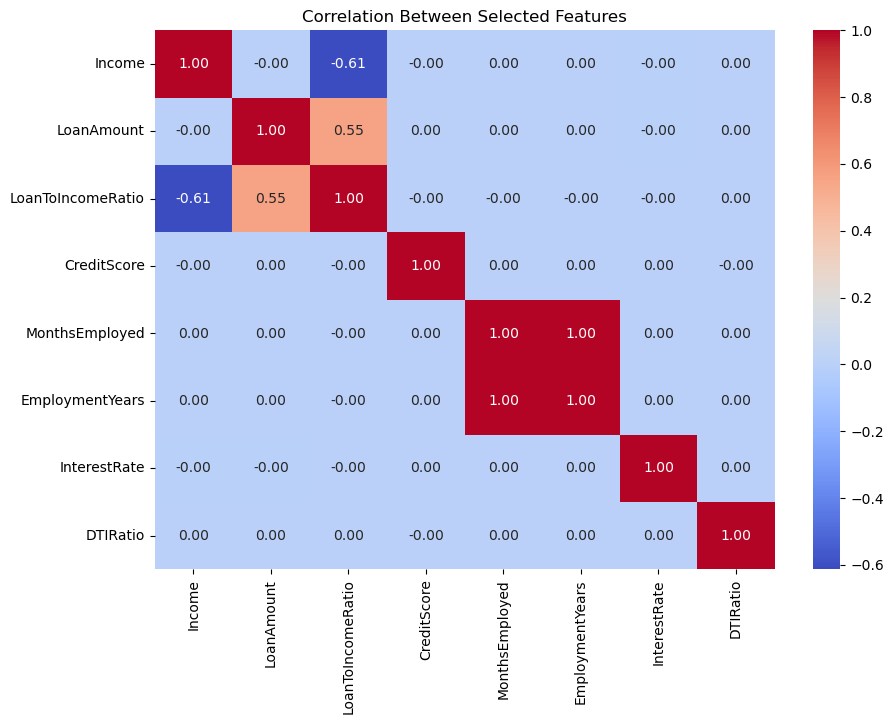

In [24]:
feature_check = [
    "Income",
    "LoanAmount",
    "LoanToIncomeRatio",
    "CreditScore",
    "MonthsEmployed",
    "EmploymentYears",
    "InterestRate",
    "DTIRatio"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df_model[feature_check].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Selected Features")

plt.show()

In [25]:
df_model.drop(
    columns=["MonthlyIncome", "EmploymentYears"],
    inplace=True
)

In [26]:
df_model.drop(
    columns=["CreditRiskBand", "DTIRiskBand"],
    inplace=True
)

## Check the final feature list

In [27]:
df_model.columns.tolist()

['Age',
 'Income',
 'LoanAmount',
 'CreditScore',
 'MonthsEmployed',
 'NumCreditLines',
 'InterestRate',
 'LoanTerm',
 'DTIRatio',
 'Education',
 'EmploymentType',
 'MaritalStatus',
 'HasMortgage',
 'HasDependents',
 'LoanPurpose',
 'HasCoSigner',
 'Default',
 'LoanToIncomeRatio']

## Separate X and y

In [28]:
X = df_model.drop(columns=["Default"])
y = df_model["Default"]

In [29]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (255347, 17)
y shape: (255347,)


## Identify numerical and categorical features

In [30]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'LoanToIncomeRatio']

Categorical Features:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


## Save the feature-engineered dataset

In [31]:
df_model.to_csv(
    "../data/processed/loan_data_feature_engineered.csv",
    index=False
)

OSError: Cannot save file into a non-existent directory: '..\data\processed'